# LAB 1 - How to Store an AI Dataset?
## Data Storage Methods in AI Systems
**Group members:**  
**Rinkle Sharma - Student ID: 67784**  
**Saisri Akkireddi - Student ID: 66918**  
**Submission: Group of two students**

This report follows Tasks 1-6 of the supplied laboratory instruction. All numerical results and plots are produced by the executed code in this notebook. The synthetic dataset contains 100,000 rows. Timing results describe this execution environment, not guaranteed performance on other computers.

Reproduction: install `pandas numpy pyarrow duckdb matplotlib`, then run all cells in order. The notebook creates its datasets in a local `lab1_data` directory; no external input data is needed. Outputs already included below allow review without rerunning.

## Environment and experimental method
A fixed random seed makes the dataset reproducible. Every timed comparison uses five measured repetitions after an untimed warm-up. `perf_counter` measures wall-clock time. Format order is shuffled within each repetition for Task 3 and Task 4. Full file read and write timings include serialization/conversion but exclude data generation and plotting. Writes close the file but do not force an `fsync`; timings are not durable-disk flush benchmarks. OS caches are not cleared: reads are warm/cache-influenced. Single-process execution uses DuckDB with one thread. DataFrame results are materialized, so queries do not merely measure lazy query construction. File sizes use decimal MB (1 MB = 1,000,000 bytes).

In [1]:
import sys, platform, os
from pathlib import Path
from time import perf_counter
import numpy as np
import pandas as pd
import pyarrow
import duckdb
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML

SEED, N, REPEATS = 42, 100_000, 5
rng = np.random.default_rng(SEED)
data_dir = Path('lab1_data')
data_dir.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize': (8, 4), 'figure.dpi': 120,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 30)
versions = pd.DataFrame({'Component':['Python','OS','pandas','NumPy','PyArrow','DuckDB','Matplotlib'],
 'Version':[sys.version.split()[0],platform.platform(),pd.__version__,np.__version__,
 pyarrow.__version__,duckdb.__version__,matplotlib.__version__]})
display(versions)

def bench(fn):
    fn()  # untimed warm-up
    times = []
    for _ in range(REPEATS):
        start = perf_counter()
        result = fn()
        times.append(perf_counter() - start)
    return result, times

def stats(times):
    x = np.asarray(times)
    return {'mean_s':x.mean(), 'std_s':x.std(ddof=1),
            'min_s':x.min(), 'max_s':x.max(),
            'CV_pct':100*x.std(ddof=1)/x.mean()}

,Component,Version
0,Python,3.12.14
1,OS,Linux-6.18.44-x86_64-with-glibc2.39
2,pandas,2.2.3
3,NumPy,2.3.5
4,PyArrow,26.0.0
5,DuckDB,1.5.6
6,Matplotlib,3.10.8


## Task 1. Design the Storage Architecture of an AI System
Use stable `image_id` keys across all components. Store the binary images separately from tables; tables refer to immutable object paths and checksums. Raw images should not be embedded as base64 strings inside metadata tables. Keep a transactional catalog for updates and export versioned Parquet snapshots for analysis.

,Component,Where / format,Justification,Limitations,At 10 million images
0,Images,JPEG/PNG objects in object storage; URI + chec...,Preserves originals; scalable streaming and in...,Small-object/request overhead; network latency...,Yes; shard training inputs into tar/WebDataset...
1,Image metadata,PostgreSQL catalog + versioned Parquet analyti...,Constraints and updates in SQL; columnar scans...,Snapshot freshness; catalog indexes and partit...,Yes; partition exports; batch operations; avoi...
2,Train/validation/test split,"Versioned Parquet manifest (image_id, split, d...",Repeatable evaluation; immutable split assignm...,Changing data needs a new version; class balan...,Yes; partition by dataset version; avoid reshu...
3,Model predictions and class probabilities,Parquet by model version/run; image_id + predi...,Append-only outputs; efficient scans; supports...,"Storage grows with images, classes, and versio...","Yes; compact batches; partition by run, not in..."
4,512-dimensional embeddings,Float32 NumPy/memory-mapped shards + id manife...,Contiguous tensors for training; index gives a...,Index RAM/recall tradeoff; align vector rows w...,Yes; sharded vectors and distributed/disk-back...
5,Model information,Immutable model weights in object storage; reg...,Traceable versions; framework/config/label map...,Large checkpoints and incompatible framework v...,Yes; lifecycle retention and promotion policie...
6,Experiment information,MLflow-style tracking: SQL runs/metrics + obje...,"Links parameters, seed, code commit, environme...",Logging overhead; artifact growth; access cont...,Yes; batch metrics and apply artifact retention


,Images,512D float32 embeddings GB,Image objects GB at assumed 200 KB each
0,100000,0.2048,20.0
1,10000000,20.4800,2000.0


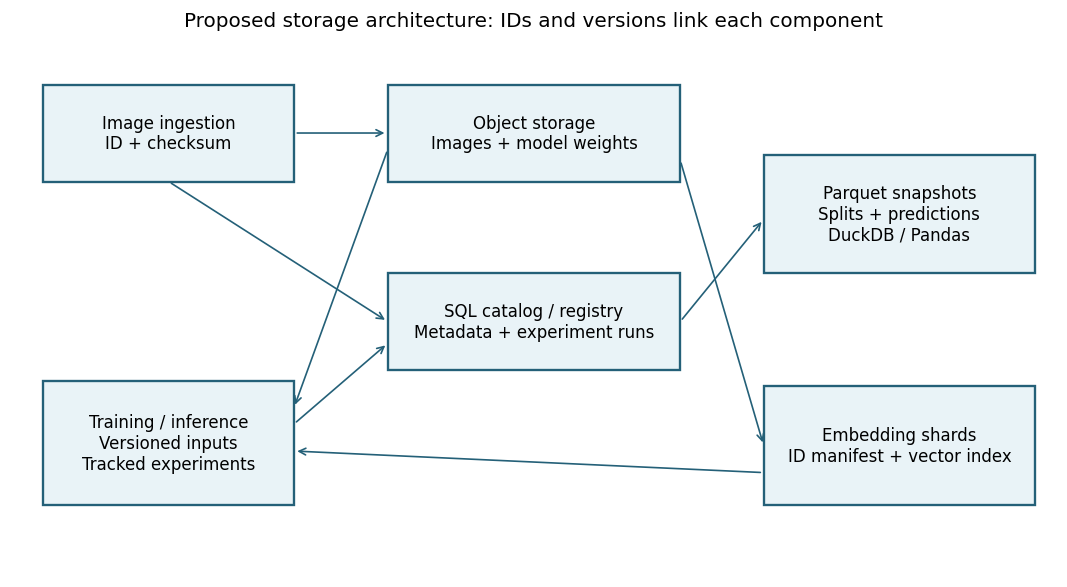

In [2]:
architecture = pd.DataFrame([
 ['Images','JPEG/PNG objects in object storage; URI + checksum in catalog',
  'Preserves originals; scalable streaming and independent access',
  'Small-object/request overhead; network latency; backup cost',
  'Yes; shard training inputs into tar/WebDataset packs; retain originals'],
 ['Image metadata','PostgreSQL catalog + versioned Parquet analytical snapshots',
  'Constraints and updates in SQL; columnar scans in snapshots',
  'Snapshot freshness; catalog indexes and partition maintenance',
  'Yes; partition exports; batch operations; avoid one huge file'],
 ['Train/validation/test split','Versioned Parquet manifest (image_id, split, dataset_version)',
  'Repeatable evaluation; immutable split assignments; leakage checks',
  'Changing data needs a new version; class balance must be audited',
  'Yes; partition by dataset version; avoid reshuffling established test sets'],
 ['Model predictions and class probabilities',
  'Parquet by model version/run; image_id + predicted_class + class probability vector',
  'Append-only outputs; efficient scans; supports comparing model versions',
  'Storage grows with images, classes, and versions; tiny partitions hurt',
  'Yes; compact batches; partition by run, not individual image_id'],
 ['512-dimensional embeddings','Float32 NumPy/memory-mapped shards + id manifest; vector index if similarity search is needed',
  'Contiguous tensors for training; index gives approximate nearest-neighbor search',
  'Index RAM/recall tradeoff; align vector rows with ids and encoder version',
  'Yes; sharded vectors and distributed/disk-backed search; cost increases'],
 ['Model information','Immutable model weights in object storage; registry metadata in SQL/JSON',
  'Traceable versions; framework/config/label map and checksum retained',
  'Large checkpoints and incompatible framework versions',
  'Yes; lifecycle retention and promotion policies needed'],
 ['Experiment information','MLflow-style tracking: SQL runs/metrics + object-store artifacts',
  'Links parameters, seed, code commit, environment and dataset to a run',
  'Logging overhead; artifact growth; access control and retention',
  'Yes; batch metrics and apply artifact retention']
], columns=['Component','Where / format','Justification','Limitations','At 10 million images'])
display(architecture)

# Storage estimates: decimal GB, uncompressed vectors only.
sizes = pd.DataFrame({'Images':[100_000,10_000_000]})
sizes['512D float32 embeddings GB'] = sizes.Images * 512 * 4 / 1e9
sizes['Image objects GB at assumed 200 KB each'] = sizes.Images * 200_000 / 1e9
display(sizes)

fig, ax = plt.subplots(figsize=(9, 5))
ax.axis('off')
boxes = {
 'ingest':(.03,.73,.24,.18,'Image ingestion\nID + checksum'),
 'images':(.36,.73,.28,.18,'Object storage\nImages + model weights'),
 'catalog':(.36,.38,.28,.18,'SQL catalog / registry\nMetadata + experiment runs'),
 'tables':(.72,.56,.26,.22,'Parquet snapshots\nSplits + predictions\nDuckDB / Pandas'),
 'vectors':(.72,.13,.26,.22,'Embedding shards\nID manifest + vector index'),
 'training':(.03,.13,.24,.23,'Training / inference\nVersioned inputs\nTracked experiments')}
for x,y,w,h,label in boxes.values():
 ax.add_patch(plt.Rectangle((x,y),w,h,facecolor='#e9f3f7',edgecolor='#246078',lw=1.4))
 ax.text(x+w/2,y+h/2,label,ha='center',va='center',fontsize=10)
for a,b in [((.27,.82),(.36,.82)),((.15,.73),(.36,.47)),
            ((.64,.47),(.72,.66)),((.64,.77),(.72,.24)),
            ((.36,.79),(.27,.31)),((.72,.19),(.27,.23)),
            ((.27,.28),(.36,.43))]:
 ax.annotate('',xy=b,xytext=a,arrowprops={'arrowstyle':'->','color':'#246078'})
ax.set_xlim(0,1); ax.set_ylim(0,1)
ax.set_title('Proposed storage architecture: IDs and versions link each component')
plt.tight_layout(); plt.show()

The main likely storage problem at 10 million images is the image payload and image delivery throughput: at the explicit assumption of 200 KB per compressed image, originals occupy about 2,000 GB before replicas, versus 20.48 GB for one set of 512D float32 embeddings. The assumption is illustrative, not a measured image size. Many small files can bottleneck training; sharding, prefetching and caching help. A vector index may become the main RAM/query problem for similarity search, while repeated predictions can dominate if many classes and model versions are retained.

Separate dataset versions from model versions. Store experiment run IDs, label ordering for probability vectors, preprocessing settings and embedding encoder versions. Enforce unique IDs, disjoint splits and frozen evaluation manifests. Limit permissions and retain backups. The synthetic confidence field used below is a prediction score, not proof of accuracy or calibrated probability.

## Task 2. Prepare Data for the Experiment
Generate an imbalanced five-class dataset with realistic resolution pairs and source labels. Split probabilities are 75% train, 15% validation and 10% test; sampled counts vary slightly. Model versions use a common score distribution, so differences in mean confidence are sampling effects, not evidence that one version is more accurate.

In [3]:
resolutions = np.array([[640,480],[1280,720],[1920,1080],
                        [1024,768],[800,600],[512,512],[224,224]])
resolution_idx = rng.choice(len(resolutions), N,
                            p=[.20,.22,.16,.12,.10,.12,.08])
df = pd.DataFrame({
 'image_id': np.arange(1,N+1,dtype=np.int64),
 'filename': [f'image_{i:06d}.jpg' for i in range(1,N+1)],
 'category': rng.choice(['cat','dog','car','person','other'],N,
                        p=[.22,.28,.18,.24,.08]),
 'width': resolutions[resolution_idx,0],
 'height': resolutions[resolution_idx,1],
 'source': rng.choice(['open_dataset','camera','web'],N,p=[.55,.30,.15]),
 'split': rng.choice(['train','validation','test'],N,p=[.75,.15,.10]),
 'confidence': np.round(rng.beta(5,2,N),6),
 'model_version': rng.choice(['v1','v2','v3'],N,p=[.25,.35,.40])
})
assert df.shape == (100_000,9) and df.image_id.is_unique
assert df.confidence.between(0,1).all() and not df.isna().any().any()
assert (df[['width','height']] > 0).all().all()
print('Rows:',len(df),' Columns:',len(df.columns))
display(df.head())
display(df.dtypes.astype(str).rename('dtype').rename_axis('column').reset_index())
display(df.category.value_counts().rename_axis('category').reset_index(name='records'))
display(df.split.value_counts().rename_axis('split').reset_index(name='records'))

Rows: 100000  Columns: 9


,image_id,filename,category,width,height,source,split,confidence,model_version
0,1,image_000001.jpg,other,800,600,open_dataset,train,0.691461,v2
1,2,image_000002.jpg,other,1920,1080,open_dataset,train,0.639756,v3
2,3,image_000003.jpg,car,512,512,web,validation,0.926643,v3
3,4,image_000004.jpg,dog,1024,768,camera,train,0.831371,v2
4,5,image_000005.jpg,person,640,480,camera,train,0.680318,v3


,column,dtype
0,image_id,int64
1,filename,object
2,category,object
3,width,int64
4,height,int64
5,source,object
6,split,object
7,confidence,float64
8,model_version,object


,category,records
0,dog,28109
1,person,23848
2,cat,22120
3,car,17857
4,other,8066


,split,records
0,train,75144
1,validation,14885
2,test,9971


## Task 3. CSV vs JSON vs Parquet
CSV is UTF-8 with a header and no index. JSON uses records orientation without indentation and 15-digit float precision. Parquet uses PyArrow, Snappy compression, no index, and 25,000-row row groups. Compression is part of the configured-format comparison: these results do not isolate column layout from compression. Data types are normalized for equality checks and Task 4, with confidence equality checked to absolute tolerance 1e-12.

Timing variability (sample standard deviation, minimum, maximum):
Parquet is 62.28% smaller than CSV (negative means larger).


,Format,File_size_MB,Average_write_s,Average_read_s
0,csv,6.480755,0.223863,0.075254
1,json,17.280678,0.124168,0.306326
2,parquet,2.444253,0.056448,0.035253


,Format,Run,Write_s,Read_s,Size_MB
0,json,1,0.126536,0.294533,17.280678
1,parquet,1,0.054378,0.045141,2.444253
2,csv,1,0.242377,0.075050,6.480755
3,parquet,2,0.057757,0.027442,2.444253
4,json,2,0.125279,0.310826,17.280678
5,csv,2,0.217132,0.081663,6.480755
6,parquet,3,0.054965,0.027981,2.444253
7,json,3,0.117957,0.310817,17.280678
8,csv,3,0.210011,0.083988,6.480755
9,parquet,4,0.062497,0.033441,2.444253


Write_s                        Read_s                    
              std       min       max       std       min       max
Format                                                             
csv      0.012372  0.210011  0.242377  0.008072  0.063806  0.083988
json     0.008634  0.114375  0.136694  0.006940  0.294533  0.310826
parquet  0.003849  0.052645  0.062497  0.008125  0.027442  0.045141

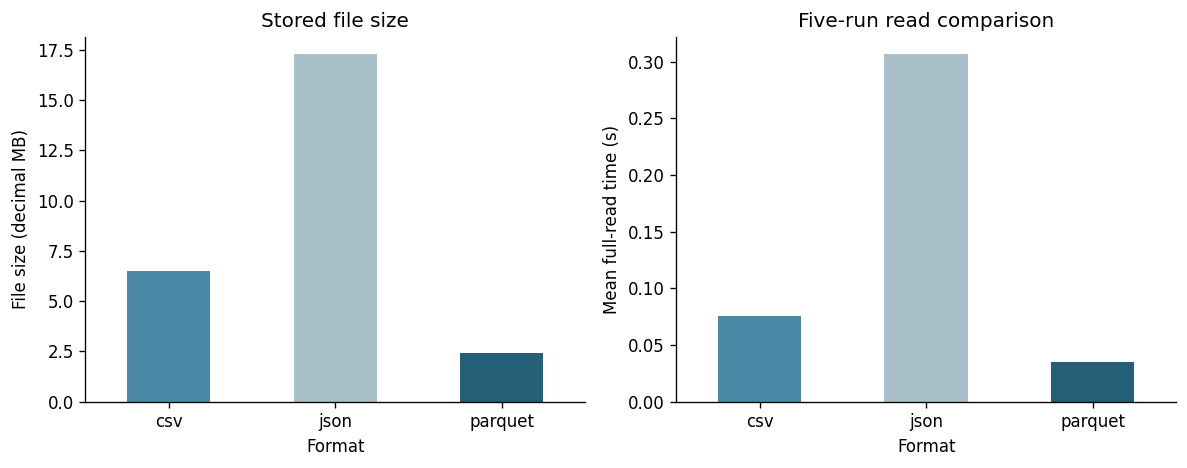

**Measured conclusions:**
1. Parquet changes storage size by 62.28% relative to CSV; repeated string values and Snappy compression help reduce this workload's footprint.
2. The fastest mean full read was **parquet**; Parquet/CSV read-time ratio was 0.468.
3. The fastest mean write was **parquet**. Read and write rankings need not be the same; JSON repeats field names and requires text parsing.
4. The largest read-time coefficient of variation was 23.0%, and the largest max/min timing ratio was 1.64. Repetitions therefore differ; these are descriptive spread measures, not a statistical significance test. Five runs and warm caches limit generalization.

In [4]:
paths = {fmt:data_dir / f'dataset.{fmt}' for fmt in ['csv','json','parquet']}
text_cols = ['filename','category','source','split','model_version']
int_cols = ['image_id','width','height']
def normalize(frame):
    return frame.astype({**{k:'object' for k in text_cols},
                         **{k:'int64' for k in int_cols},'confidence':'float64'})
def write_format(fmt):
    if fmt == 'csv': df.to_csv(paths[fmt],index=False)
    elif fmt == 'json': df.to_json(paths[fmt],orient='records',double_precision=15)
    else: df.to_parquet(paths[fmt],engine='pyarrow',compression='snappy',
                       index=False,row_group_size=25_000)
def read_format(fmt):
    if fmt == 'csv': return pd.read_csv(paths[fmt])
    if fmt == 'json': return pd.read_json(paths[fmt],orient='records')
    return pd.read_parquet(paths[fmt],engine='pyarrow')

for fmt in paths:
    write_format(fmt); read_format(fmt)  # warm-up
raw3 = []
order_rng = np.random.default_rng(SEED+1)
for repeat in range(1,REPEATS+1):
    for fmt in order_rng.permutation(list(paths)):
        start = perf_counter(); write_format(fmt); wt = perf_counter()-start
        start = perf_counter(); loaded = read_format(fmt); rt = perf_counter()-start
        pd.testing.assert_frame_equal(df,normalize(loaded),check_exact=False,
                                      rtol=0,atol=1e-12)
        raw3.append([fmt,repeat,wt,rt,paths[fmt].stat().st_size/1e6])
raw3 = pd.DataFrame(raw3,columns=['Format','Run','Write_s','Read_s','Size_MB'])
comparison3 = raw3.groupby('Format').agg(
 File_size_MB=('Size_MB','mean'),Average_write_s=('Write_s','mean'),
 Average_read_s=('Read_s','mean')).reindex(['csv','json','parquet'])
display(comparison3.reset_index().round(6))
display(raw3.round(6))
variability3 = raw3.groupby('Format')[['Write_s','Read_s']].agg(['std','min','max'])
print('Timing variability (sample standard deviation, minimum, maximum):')
display(variability3.round(6))
saving_pct = 100*(1-comparison3.loc['parquet','File_size_MB']/
                    comparison3.loc['csv','File_size_MB'])
print(f'Parquet is {saving_pct:.2f}% smaller than CSV (negative means larger).')

fig, axes = plt.subplots(1,2,figsize=(10,4))
comparison3.File_size_MB.plot.bar(ax=axes[0],color=['#4989a6','#a9bfca','#246078'])
axes[0].set_ylabel('File size (decimal MB)'); axes[0].set_title('Stored file size')
comparison3.Average_read_s.plot.bar(ax=axes[1],color=['#4989a6','#a9bfca','#246078'])
axes[1].set_ylabel('Mean full-read time (s)'); axes[1].set_title('Five-run read comparison')
for ax in axes: ax.tick_params(axis='x',rotation=0); ax.set_xlabel('Format')
plt.tight_layout(); plt.show()

fast_write = comparison3.Average_write_s.idxmin()
fast_read = comparison3.Average_read_s.idxmin()
ratios = raw3.groupby('Format')[['Write_s','Read_s']].agg(lambda x: x.max()/x.min())
read_cv = raw3.groupby('Format').Read_s.agg(lambda x:100*x.std()/x.mean())
display(Markdown(f"""**Measured conclusions:**
1. Parquet changes storage size by {saving_pct:.2f}% relative to CSV; repeated string values and Snappy compression help reduce this workload's footprint.
2. The fastest mean full read was **{fast_read}**; Parquet/CSV read-time ratio was {comparison3.loc['parquet','Average_read_s']/comparison3.loc['csv','Average_read_s']:.3f}.
3. The fastest mean write was **{fast_write}**. Read and write rankings need not be the same; JSON repeats field names and requires text parsing.
4. The largest read-time coefficient of variation was {read_cv.max():.1f}%, and the largest max/min timing ratio was {ratios.to_numpy().max():.2f}. Repetitions therefore differ; these are descriptive spread measures, not a statistical significance test. Five runs and warm caches limit generalization."""))

## Task 4. Does the Storage Format Affect Data Analysis?
Measure two different quantities: operation-only time after a normalized DataFrame is loaded, and end-to-end read + normalization + operation time. File parsing is excluded from the first and included in the second. Identical DataFrames remove dtype differences as a confounder. Large filtered results are summarized by exact record counts and first-five-row previews; the code returns the complete selected DataFrames.

In [5]:
operations = {
 'A: category cat':lambda x:x.loc[x.category.eq('cat')],
 'B: cat, confidence > 0.9, test':lambda x:x.loc[
     x.category.eq('cat') & x.confidence.gt(.9) & x.split.eq('test')],
 'C: category aggregation':lambda x:x.groupby('category',sort=True).agg(
     number_of_images=('image_id','size'),average_confidence=('confidence','mean'),
     minimum_confidence=('confidence','min'),maximum_confidence=('confidence','max')).reset_index(),
 'D: model version mean':lambda x:x.groupby('model_version',sort=True).confidence.mean()
     .reset_index(name='average_confidence')
}
reference = {name:fn(df) for name,fn in operations.items()}
for name,result in reference.items():
    print(name,'- result rows:',len(result))
    display(result.head() if name.startswith(('A:','B:')) else result)
frames = {fmt:normalize(read_format(fmt)) for fmt in paths}
for frame in frames.values():
    pd.testing.assert_frame_equal(df,frame,check_exact=False,rtol=0,atol=1e-12)
raw4 = []
for fmt in paths:
    for fn in operations.values(): fn(frames[fmt]); fn(normalize(read_format(fmt)))
for repeat in range(1,REPEATS+1):
    for fmt in order_rng.permutation(list(paths)):
        for name,fn in operations.items():
            start=perf_counter(); result=fn(frames[fmt]); op=perf_counter()-start
            start=perf_counter(); end_result=fn(normalize(read_format(fmt))); total=perf_counter()-start
            pd.testing.assert_frame_equal(result,reference[name],check_exact=False,atol=1e-12,rtol=0)
            pd.testing.assert_frame_equal(end_result,reference[name],check_exact=False,atol=1e-12,rtol=0)
            raw4.append([fmt,name,repeat,op,total])
raw4=pd.DataFrame(raw4,columns=['Format','Operation','Run','Operation_only_s','Read_plus_operation_s'])
timing4=raw4.groupby(['Operation','Format'])[['Operation_only_s','Read_plus_operation_s']].mean()
display(timing4.reset_index().round(6))
print('All four analyses agree across the three formats.')

A: category cat - result rows: 22120
B: cat, confidence > 0.9, test - result rows: 270
C: category aggregation - result rows: 5
D: model version mean - result rows: 3
All four analyses agree across the three formats.


,image_id,filename,category,width,height,source,split,confidence,model_version
13,14,image_000014.jpg,cat,512,512,camera,train,0.418930,v2
16,17,image_000017.jpg,cat,1920,1080,camera,train,0.632017,v3
19,20,image_000020.jpg,cat,1024,768,open_dataset,train,0.852250,v1
24,25,image_000025.jpg,cat,800,600,camera,train,0.565052,v2
25,26,image_000026.jpg,cat,640,480,open_dataset,train,0.507335,v3


,image_id,filename,category,width,height,source,split,confidence,model_version
247,248,image_000248.jpg,cat,1280,720,camera,test,0.926924,v1
373,374,image_000374.jpg,cat,1280,720,open_dataset,test,0.935608,v3
560,561,image_000561.jpg,cat,640,480,open_dataset,test,0.985734,v2
634,635,image_000635.jpg,cat,640,480,open_dataset,test,0.920167,v3
688,689,image_000689.jpg,cat,800,600,open_dataset,test,0.910126,v1


,category,number_of_images,average_confidence,minimum_confidence,maximum_confidence
0,car,17857,0.713492,0.118501,0.998041
1,cat,22120,0.714806,0.120929,0.997565
2,dog,28109,0.713861,0.077076,0.997734
3,other,8066,0.714087,0.132371,0.996192
4,person,23848,0.714635,0.051652,0.999452


,model_version,average_confidence
0,v1,0.714380
1,v2,0.714176
2,v3,0.714127


,Operation,Format,Operation_only_s,Read_plus_operation_s
0,A: category cat,csv,0.007243,0.090442
1,A: category cat,json,0.018881,0.515203
2,A: category cat,parquet,0.007102,0.043330
3,"B: cat, confidence > 0.9, test",csv,0.010187,0.095507
4,"B: cat, confidence > 0.9, test",json,0.030929,0.546366
5,"B: cat, confidence > 0.9, test",parquet,0.010203,0.044297
6,C: category aggregation,csv,0.006675,0.089144
7,C: category aggregation,json,0.017006,0.521563
8,C: category aggregation,parquet,0.006762,0.043308
9,D: model version mean,csv,0.003483,0.087720


**Interpretation:** Once the whole file has been loaded and normalized, Pandas operates on its in-memory representation. The original CSV/JSON/Parquet label is no longer a direct cause of filtering speed. Small operation-only differences reflect runtime variation and allocation effects. End-to-end timings retain the cost of parsing, conversion and loading, so file format still matters. Confidence aggregates describe score distributions; they do not measure classification accuracy because no ground-truth/prediction comparison is performed.

## Task 5. Parquet + DuckDB - Querying Data Directly
Each SQL query reads the generated Parquet file directly and materializes its result using `fetchdf()`. Counts and group means are sorted for deterministic output. Confidence ties in Query 4 are broken by image ID, and mean ties in Query 5 by category/model version. All five SQL queries and their results follow.

In [6]:
con=duckdb.connect(database=':memory:')
con.execute('SET threads=1')
parquet_sql = "'"+paths['parquet'].as_posix().replace("'", "''")+"'"
queries = {
 'Query 1 - dog, confidence > 0.95, test': f"""
SELECT * FROM {parquet_sql}
WHERE category = 'dog' AND confidence > 0.95 AND split = 'test'
ORDER BY image_id;""",
 'Query 2 - counts': f"""
SELECT category, COUNT(*) AS number_of_records FROM {parquet_sql}
GROUP BY category ORDER BY category;""",
 'Query 3 - mean confidence': f"""
SELECT category, AVG(confidence) AS average_confidence FROM {parquet_sql}
GROUP BY category ORDER BY category;""",
 'Query 4 - lowest confidence': f"""
SELECT image_id, category, confidence, model_version FROM {parquet_sql}
ORDER BY confidence ASC, image_id ASC LIMIT 10;""",
 'Query 5 - highest mean combination': f"""
SELECT category, model_version, AVG(confidence) AS average_confidence
FROM {parquet_sql}
GROUP BY category, model_version
ORDER BY average_confidence DESC, category ASC, model_version ASC LIMIT 1;"""
}
results5={}
for name,sql in queries.items():
    print(name); print(sql.strip())
    result=con.execute(sql).fetchdf(); results5[name]=result
    print('Result records:',len(result))
    display(result.head(10) if name.startswith('Query 1') else result)
# The complete Query 1 result is embedded below as a separate full table.
print('Complete Query 1 result:')
display(HTML(results5[next(iter(queries))].to_html(index=False)))

Query 1 - dog, confidence > 0.95, test
SELECT * FROM 'lab1_data/dataset.parquet'
WHERE category = 'dog' AND confidence > 0.95 AND split = 'test'
ORDER BY image_id;
Result records: 78
Query 2 - counts
SELECT category, COUNT(*) AS number_of_records FROM 'lab1_data/dataset.parquet'
GROUP BY category ORDER BY category;
Result records: 5
Query 3 - mean confidence
SELECT category, AVG(confidence) AS average_confidence FROM 'lab1_data/dataset.parquet'
GROUP BY category ORDER BY category;
Result records: 5
Query 4 - lowest confidence
SELECT image_id, category, confidence, model_version FROM 'lab1_data/dataset.parquet'
ORDER BY confidence ASC, image_id ASC LIMIT 10;
Result records: 10
Query 5 - highest mean combination
SELECT category, model_version, AVG(confidence) AS average_confidence
FROM 'lab1_data/dataset.parquet'
GROUP BY category, model_version
ORDER BY average_confidence DESC, category ASC, model_version ASC LIMIT 1;
Result records: 1
Complete Query 1 result:


,image_id,filename,category,width,height,source,split,confidence,model_version
0,1026,image_001026.jpg,dog,1280,720,camera,test,0.961814,v3
1,1470,image_001470.jpg,dog,640,480,open_dataset,test,0.955555,v1
2,3441,image_003441.jpg,dog,1280,720,open_dataset,test,0.969577,v2
3,5769,image_005769.jpg,dog,1280,720,camera,test,0.957464,v2
4,5902,image_005902.jpg,dog,640,480,camera,test,0.953260,v3
5,7655,image_007655.jpg,dog,1280,720,open_dataset,test,0.951921,v3
6,8933,image_008933.jpg,dog,640,480,open_dataset,test,0.958073,v2
7,9775,image_009775.jpg,dog,800,600,open_dataset,test,0.977267,v1
8,10508,image_010508.jpg,dog,640,480,open_dataset,test,0.967630,v3
9,17261,image_017261.jpg,dog,1024,768,web,test,0.977924,v3


,category,number_of_records
0,car,17857
1,cat,22120
2,dog,28109
3,other,8066
4,person,23848


,category,average_confidence
0,car,0.713492
1,cat,0.714806
2,dog,0.713861
3,other,0.714087
4,person,0.714635


,image_id,category,confidence,model_version
0,89195,person,0.051652,v2
1,63943,dog,0.077076,v2
2,71336,person,0.086010,v2
3,72325,person,0.089446,v3
4,53586,person,0.091755,v3
5,59134,person,0.104469,v3
6,18243,dog,0.105202,v3
7,9164,car,0.118501,v3
8,4313,person,0.119917,v3
9,56769,cat,0.120929,v3


,category,model_version,average_confidence
0,other,v2,0.720575


image_id,filename,category,width,height,source,split,confidence,model_version
1026,image_001026.jpg,dog,1280,720,camera,test,0.961814,v3
1470,image_001470.jpg,dog,640,480,open_dataset,test,0.955555,v1
3441,image_003441.jpg,dog,1280,720,open_dataset,test,0.969577,v2
5769,image_005769.jpg,dog,1280,720,camera,test,0.957464,v2
5902,image_005902.jpg,dog,640,480,camera,test,0.953260,v3
7655,image_007655.jpg,dog,1280,720,open_dataset,test,0.951921,v3
8933,image_008933.jpg,dog,640,480,open_dataset,test,0.958073,v2
9775,image_009775.jpg,dog,800,600,open_dataset,test,0.977267,v1
10508,image_010508.jpg,dog,640,480,open_dataset,test,0.967630,v3
17261,image_017261.jpg,dog,1024,768,web,test,0.977924,v3


In [7]:
def pandas_filter(x):
    return x.loc[x.category.eq('dog') & x.confidence.gt(.95) & x.split.eq('test')]
def pandas_aggregate(x):
    return x.groupby('category',sort=True).confidence.mean().reset_index(name='average_confidence')
q1,q2,q3,q4,q5 = list(queries.values())
p_filter = pandas_filter(df).sort_values('image_id').reset_index(drop=True)
p_counts = df.groupby('category',sort=True).size().reset_index(name='number_of_records')
p_lowest = df.sort_values(['confidence','image_id']).head(10)[
    ['image_id','category','confidence','model_version']].reset_index(drop=True)
p_best = df.groupby(['category','model_version'],sort=True).confidence.mean().reset_index(
    name='average_confidence').sort_values(
    ['average_confidence','category','model_version'],ascending=[False,True,True]).head(1).reset_index(drop=True)
for actual,expected in zip(results5.values(),
 [p_filter,p_counts,pandas_aggregate(df),p_lowest,p_best]):
    pd.testing.assert_frame_equal(actual,expected,check_dtype=False,
                                  check_exact=False,rtol=0,atol=1e-12)
print('All five DuckDB results match equivalent Pandas results.')

raw5=[]
for operation,fn,sql in [('Filtering',pandas_filter,q1),('Aggregation',pandas_aggregate,q3)]:
    runners={
      'Pandas preloaded':lambda fn=fn:fn(df),
      'Pandas full read + operation':lambda fn=fn:fn(pd.read_parquet(paths['parquet'])),
      'DuckDB direct Parquet':lambda sql=sql:con.execute(sql).fetchdf()
    }
    for engine,runner in runners.items():
        result,times=bench(runner)
        for run,t in enumerate(times,1): raw5.append([operation,engine,run,t])
raw5=pd.DataFrame(raw5,columns=['Operation','Approach','Run','Time_s'])
timing5=raw5.groupby(['Operation','Approach']).Time_s.agg(['mean','std','min','max'])
display(timing5.reset_index().round(6))
display(raw5.round(6))
for operation in ['Filtering','Aggregation']:
    t=timing5.loc[operation,'mean']
    ratio=t['Pandas full read + operation']/t['DuckDB direct Parquet']
    print(f'{operation}: Pandas full-read / DuckDB time ratio = {ratio:.2f}; '
          'above 1 means DuckDB was faster in this experiment.')

All five DuckDB results match equivalent Pandas results.
Filtering: Pandas full-read / DuckDB time ratio = 5.74; above 1 means DuckDB was faster in this experiment.
Aggregation: Pandas full-read / DuckDB time ratio = 17.75; above 1 means DuckDB was faster in this experiment.


,Operation,Approach,mean,std,min,max
0,Aggregation,DuckDB direct Parquet,0.001974,0.000146,0.001850,0.002184
1,Aggregation,Pandas full read + operation,0.035043,0.001251,0.033439,0.036433
2,Aggregation,Pandas preloaded,0.004094,0.000218,0.003832,0.004323
3,Filtering,DuckDB direct Parquet,0.006703,0.000254,0.006373,0.007006
4,Filtering,Pandas full read + operation,0.038464,0.001434,0.036802,0.039748
5,Filtering,Pandas preloaded,0.009626,0.000338,0.009362,0.010186


,Operation,Approach,Run,Time_s
0,Filtering,Pandas preloaded,1,0.009687
1,Filtering,Pandas preloaded,2,0.009390
2,Filtering,Pandas preloaded,3,0.009362
3,Filtering,Pandas preloaded,4,0.010186
4,Filtering,Pandas preloaded,5,0.009504
5,Filtering,Pandas full read + operation,1,0.037058
6,Filtering,Pandas full read + operation,2,0.039009
7,Filtering,Pandas full read + operation,3,0.039702
8,Filtering,Pandas full read + operation,4,0.036802
9,Filtering,Pandas full read + operation,5,0.039748


### Task 5. Answers to the four questions
1. **Must DuckDB load everything?** No. It can scan needed columns and evaluate predicates during a Parquet scan without first making a full Pandas DataFrame. Metadata can let it skip row groups whose value ranges cannot satisfy a predicate. Filtering is not a guarantee that only matching rows are read: this randomly mixed dataset may require scanning many or all row groups. `SELECT *` needs every column for output, whereas an aggregation can read fewer columns.
2. **Why read fewer rows/columns?** This reduces bytes read, decompression, conversion, memory and potentially network transfer. Savings depend on selectivity, row-group layout and the query; output materialization still costs time.
3. **When prefer Pandas?** Exploratory transformations, plotting and ML workflows on data that fits RAM, especially when many operations reuse an already-loaded DataFrame. Its operation-only timings exclude the initial read and must not be confused with end-to-end cost.
4. **When prefer DuckDB?** SQL filtering/aggregation over Parquet, queries combining many files, or work where returning a small result avoids constructing the full dataset in RAM. Direct execution still has startup and result-conversion overhead, so it need not always be faster. Pandas can also pass selected columns and filters to a Parquet reader; the full-read baseline is a workflow comparison, not a claim that Pandas cannot optimize I/O.

The two measured SQL workloads are compared both against preloaded Pandas and against Pandas including its file read. DuckDB Query 1 sorts its output by ID, while the synthetic DataFrame is already in ID order, so this includes a small additional SQL ordering cost. A single-thread connection and warm cache make the scope explicit.

## Task 6. I Do Not Need the Entire Dataset - Column Pruning
Compare A (read every column, then select three) with B (read only three columns). Repeat with a wider 24-column dataset containing 15 additional float32 sensor/feature columns. These are experimental numeric features, not a replacement for the 512D embeddings discussed in Task 1. Both approaches return equal selected values and use five measurements after warm-up.

Original: A/B=8.46; B time reduction=88.2%
Extended: A/B=8.51; B time reduction=88.2%


,Dataset,Columns,Approach,Average_s,Std_s,Min_s,Max_s,File_MB
0,Extended,24,A: full read then select,0.035316,0.001434,0.033945,0.037509,11.280424
1,Extended,24,B: read selected columns,0.004150,0.000296,0.003856,0.004516,11.280424
2,Original,9,A: full read then select,0.032993,0.002952,0.030878,0.038155,2.444253
3,Original,9,B: read selected columns,0.003900,0.000342,0.003568,0.004281,2.444253


,Dataset,Columns,Approach,Run,Time_s,File_MB
0,Original,9,A: full read then select,1,0.032176,2.444253
1,Original,9,A: full read then select,2,0.038155,2.444253
2,Original,9,A: full read then select,3,0.032414,2.444253
3,Original,9,A: full read then select,4,0.030878,2.444253
4,Original,9,A: full read then select,5,0.031341,2.444253
5,Original,9,B: read selected columns,1,0.004281,2.444253
6,Original,9,B: read selected columns,2,0.004259,2.444253
7,Original,9,B: read selected columns,3,0.003679,2.444253
8,Original,9,B: read selected columns,4,0.003714,2.444253
9,Original,9,B: read selected columns,5,0.003568,2.444253


The relative advantage of selecting columns was **more visible** in the 24-column experiment: A/B changed from 8.46 to 8.51. This statement is based on measured means, not a guarantee; variability is shown above.

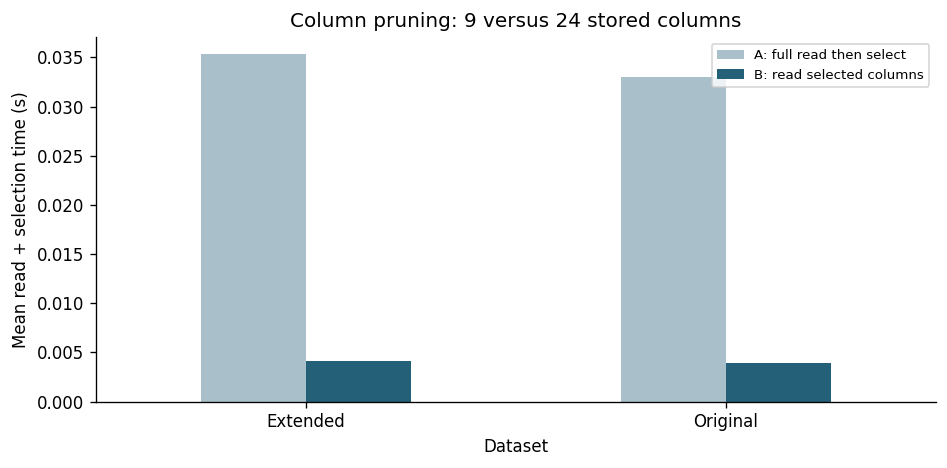

In [8]:
required=['image_id','category','confidence']
wide=df.copy()
feature_rng=np.random.default_rng(SEED+2)
for i in range(15):
    wide[f'feature_{i:02d}']=feature_rng.normal(0,1,N).astype('float32')
wide_path=data_dir/'dataset_wide.parquet'
wide.to_parquet(wide_path,index=False,engine='pyarrow',compression='snappy',
                row_group_size=25_000)
assert wide.shape==(100_000,24)
raw6=[]
for label,path,ncols in [('Original',paths['parquet'],9),('Extended',wide_path,24)]:
    result_a=pd.read_parquet(path)[required]
    result_b=pd.read_parquet(path,columns=required)
    pd.testing.assert_frame_equal(result_a,result_b)
    for approach,fn in [
     ('A: full read then select',lambda path=path:pd.read_parquet(path)[required]),
     ('B: read selected columns',lambda path=path:pd.read_parquet(path,columns=required))]:
        _,times=bench(fn)
        for run,t in enumerate(times,1):
            raw6.append([label,ncols,approach,run,t,path.stat().st_size/1e6])
raw6=pd.DataFrame(raw6,columns=['Dataset','Columns','Approach','Run','Time_s','File_MB'])
timing6=raw6.groupby(['Dataset','Columns','Approach']).agg(
 Average_s=('Time_s','mean'),Std_s=('Time_s','std'),
 Min_s=('Time_s','min'),Max_s=('Time_s','max'),File_MB=('File_MB','mean'))
display(timing6.reset_index().round(6))
display(raw6.round(6))
ratios6={}
for label in ['Original','Extended']:
    part=raw6[raw6.Dataset.eq(label)].groupby('Approach').Time_s.mean()
    a=part['A: full read then select']; b=part['B: read selected columns']
    ratios6[label]=a/b
    print(f'{label}: A/B={a/b:.2f}; B time reduction={(1-b/a)*100:.1f}%')
visible='more' if ratios6['Extended']>ratios6['Original'] else 'less'
display(Markdown(f"The relative advantage of selecting columns was **{visible} visible** "
 f"in the 24-column experiment: A/B changed from {ratios6['Original']:.2f} "
 f"to {ratios6['Extended']:.2f}. This statement is based on measured means, "
 "not a guarantee; variability is shown above."))

plot6=raw6.groupby(['Dataset','Approach']).Time_s.mean().unstack()
plot6.plot.bar(color=['#a9bfca','#246078'])
plt.ylabel('Mean read + selection time (s)')
plt.title('Column pruning: 9 versus 24 stored columns')
plt.xticks(rotation=0); plt.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Column pruning in my own words:** Tell a column-based file reader which fields the computation actually needs, so it can avoid reading and decoding unrelated fields. Selecting fields only after a full read does not avoid that work.

**AI example:** A prediction confidence report needs only image ID, category and confidence. Reading these three columns avoids loading filenames, provenance and extra numeric features. This can make repeated monitoring reports cheaper, particularly on wide or remote Parquet datasets.

## Final checks and limitations
The generated data has 100,000 records, nine base columns and 24 wide columns. Round trips and all analysis results were checked for equality. Every required timing comparison used five repetitions. Numerical scores are synthetic; no claims about a real trained model or classification quality are made. Results may vary with hardware, CPU load, package versions, compression, data layout, cache state and dataset scale. The architectural 10-million-image case is a design analysis, not an executed 10-million-row benchmark.

## References
- Supplied laboratory handout: *LAB 1 - How to Store an AI Dataset?*, Tasks 1-6.
- DuckDB documentation, *Reading and Writing Parquet Files*: https://duckdb.org/docs/current/data/parquet/overview (projection/filter pushdown).
- pandas documentation, *pandas.read_parquet*: https://pandas.pydata.org/docs/reference/api/pandas.read_parquet.html (selected columns).

Sources consulted 15 October 2026. Experiment code and numerical results are contained in this executed notebook.

In [9]:
# Keep complete numerical timing evidence locally for reproducibility.
raw3.to_csv(data_dir/'task3_raw_timings.csv',index=False)
raw4.to_csv(data_dir/'task4_raw_timings.csv',index=False)
raw5.to_csv(data_dir/'task5_raw_timings.csv',index=False)
raw6.to_csv(data_dir/'task6_raw_timings.csv',index=False)
con.close()
print('Completed Tasks 1-6; all result-equivalence assertions passed.')

Completed Tasks 1-6; all result-equivalence assertions passed.
